# PFN inference on BO contexts: is the predictive calibrated where BO queries, and what does resolution do to the labels?

## Description

<!-- Written 2026-11-12 before the first run (pre-registration). Design: research_log/decisions/0007 §4, tests 1 and 2. Issue #13. -->

**Question.**
- Three pilots found the one-step advantage over EI unpredictable from the frozen PFN's belief: api_probe, api_gate and api_decoder (notebooks 07–09).
- Decision 0007 lists four explanations:
  - E1, irreducible at decision time;
  - E2, PFN approximation error on BO contexts;
  - E3, the PFN's output resolution (1000 bins of 0.001 on the ECDF scale);
  - E4, a label metric that rewards sub-resolution differences.
- This experiment runs the two tests that need no new labels:
  - **test 2** asks whether the PFN does good inference from the data BO collects (E2);
  - **test 1** asks how the labels and the headroom depend on resolution (E3/E4).
- Test 3 (a variance-reduced lookahead, E1 vs E2) and the reference posterior (test 4) are not part of this run.

**Setup.**
- States: the 4000 labeled states of `api_round1/pilot_20261111-133311`.
  - The label set is pinned by sha256, as in notebooks 07 and 08.
  - Split 4, d = 2, n_init = 4, T = 20, one state per task, contexts n = 4 + t ≤ 23.
  - The states come from the round-1 behaviour mix: 80% EI, 10% UCB, 10% PI.
- **Test 2 (E2).** For every state, two contexts of the *same task and the same n*:
  - (a) the BO context (the state's data);
  - (b) a random design: n uniform points from a fixed per-state stream, with their noise-free f.
- Held-out points per state, the same points for both contexts:
  - 16 uniform;
  - 16 local around the BO incumbent (Gaussian, σ ∈ {0.01, 0.05, 0.2}, reflected);
  - EI's pick at the state.
  - The truth is the noise-free f.
- Per point and context:
  - the log density of f(x)'s bin;
  - the randomized PIT (CDF below the bin plus a uniform share of the bin's mass, so an exact predictive gives an exactly uniform PIT);
  - the probabilities of the improvement events {f(x) < incumbent − k bins}, k ∈ {0, 5, 20}, with their outcomes. The incumbent is the context's own.
- *Why this tests calibration validly on BO data.*
  - BO's design and the query points are chosen from the observed data only, so the design is ignorable.
  - If the PFN were the exact posterior under P0, the PIT would be uniform and the event probabilities calibrated over prior draws, for BO and random designs alike. Any deviation on BO contexts is approximation error.
  - The random design is the control. It is near the PFN's training distribution, so it shows whether a deviation is specific to BO contexts.
  - The log scores of the two designs are *not* comparable as a test of E2, because the designs carry different information. The paired log-score difference is reported descriptively only.
  - Strata defined by f\* or by f(x), such as the gap stratum or "resolvable" points, break the calibration guarantee. They are descriptive only.
  - This refines the design in decision 0007 §4, which proposed the paired log-score difference as the main quantity.
- **Test 1 (E3/E4).** By the gap stratum of the BO incumbent, (incumbent − f\*) / 0.001 in PFN bins: < 1, 1–10, 10–100, > 100. Per stratum:
  - the label split-half reliability;
  - the cross-fitted clairvoyant headroom (% of the gap) and each stratum's share of its sum;
  - the share of non-base advantages below one bin in ECDF units;
  - the within-state Spearman of log EI and of PI (at the BO context) with the label.
  - The api_decoder pilot's validation q0.5 score is joined by task seed where its validation states are among these 4000. If there are none, this is skipped and said so.
- Bootstrap: percentile CIs over states, one state per task, 200 resamples in the pilot. BO − random contrasts are paired over states.
- Precision: fp32 (tf32 off). The pilot runs all 4000 states; the sanity run uses 200 states and 50 resamples.

**What to look for.**
1. Test 2, the decision. On BO contexts, for all points pooled and for EI's picks:
   - the 50% and 90% coverage;
   - the KS distance of the PIT;
   - the ECE and calibration-in-the-large (mean predicted minus observed) of each improvement event, against the random design.
2. Test 2, descriptive:
   - PIT histograms by design and point type;
   - reliability diagrams for k = 0 and 5;
   - log density by design, point type and gap stratum.
3. Test 1: the strata table.

**GO / NO-GO.** The rule is `analysis/inference.py::inference_verdict`, on test 2, at all points pooled and at EI's picks.
- **GO (E2 supported)**: on BO contexts, for either point set, one of these holds:
  - a coverage (90% or 50%) is off nominal by ≥ 0.03 with its CI excluding nominal;
  - or some event's ECE exceeds the random design's by ≥ 0.02 with the paired CI > 0.
- **NO-GO (E2 not supported)**: for both point sets, all of these hold:
  - the coverage CIs are within nominal ± 0.03;
  - every event's BO ECE CI is below 0.03;
  - every BO − random ECE CI is below 0.02.
- **INCONCLUSIVE**: otherwise.

Readings, fixed now:
- **GO with the random design calibrated** → E2 at BO contexts: the PFN's inference degrades on the data BO collects.
- **GO with the random design also miscalibrated** → general PFN error, not specific to BO.
- **NO-GO** → the PFN is calibrated on BO data at its resolution, which leaves E1, E3 and E4. Test 1 then says how much of the label variation is below the PFN's resolution.
- **Test 1, E4 signature**:
  - most non-base advantages are below one bin;
  - the strata where the gap is < 1 bin hold most of the states.
  - Neither alone says the headroom is unreal. The headroom in % of the gap may still concentrate where the gap is large.
- **Test 1, E3 limits the PFN where the gap is small** if, in the ≥ 10-bin strata:
  - the within-state Spearman of log EI or PI with the label has a CI lower bound > 0.10;
  - while in the < 1-bin stratum it is ≈ 0, with a CI containing 0.
  - Otherwise, resolution is not what makes the advantage unpredictable.

**Limits.**
- Noise-free P0, d = 2, T = 20 only. pfn_large is valid for n ≤ 100; contexts here have n ≤ 23.
- Calibration tests marginal consistency over prior draws. A calibrated predictive can still be far from the posterior in sharpness, so NO-GO does not prove the PFN equals the posterior. That needs the reference posterior (0007 test 4).
- Exchangeable points within a state are scored together. The bootstrap resamples states, so within-state correlation is accounted for.
- The randomized PIT uses the bar distribution's within-bin uniform density. The noise-free truth inside a bin is not uniform, so near 0, where many f values cluster within one bin, the PIT is uniform only up to the within-bin shape.


### Revision after the sanity run (2026-11-12, before the pilot)

The sanity run (`results/pfn_bo_inference/sanity_20261112-083250`, 200 states, code 8f9ba21) exposed two design errors. Both are fixed before the pilot; the rule and its thresholds are unchanged.

1. **The random design's control points were not ignorable.**
   - The local points (around the *BO* incumbent) and EI's pick *at the BO state* were chosen from the BO data. For the random-design context, that is information about f outside its own context.
   - So even an exact posterior would be miscalibrated there. In the sanity run the random design underpredicted improvement at EI's picks by 0.26, which is this artefact, not PFN error.
   - **Fix:** each context gets its own points: local around its *own* incumbent, and its *own* EI pick (the engine's EI on its own candidate set, nuisance replicate 0). The uniform points stay shared.
   - BO − random contrasts compare like point types, paired over states, rather than identical points.
2. **The calibration guarantee holds for the PFN's target, not for f.**
   - pfn_large was trained to predict noisy observations y = f with the instance's preactivation and output noise, sd about 0.0003–0.0014, roughly one bin.
   - Scored against noise-free f, an exact predictive of y is over-dispersed at the bin scale.
   - **Fix:** the primary scores are computed against y, drawn from the task's own noise model with a fixed generator per group. The scores against noise-free f are kept as secondary columns (`pit_f`, `log_density_f`, `of_k*`).
   - The contexts are noise-free for both designs, as BO observes them. That is a small mismatch with the PFN's noisy training contexts, shared by both designs.
3. **New check:** the redrawn tasks reproduce the label set's observations (`check/max_abs_f_minus_label_F`).

The sanity numbers are not interpreted. The rule's verdict on them (GO) came from the flawed design.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.inference import calibrated, inference_verdict, miscalibrated
from anytime_acq.experimental.probes import within_spearman

SNAPSHOT = "results/pfn_bo_inference/pilot_20261112-084114"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=pfn_bo_inference task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261112-084114` |
| commit | `3c475a72bd0a` (tag `sweep/pfn_bo_inference/pilot_20261112-084114`) |
| backend / host | detached / ulysses |
| ran | 2026-11-12T08:41:16 → 2026-11-12T08:42:49 |
| members | 1: 1 done |
| compute | 1.6 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/pfn_bo_inference.yaml`):

```yaml
# @package _global_
# Predictive quality of the frozen PFN on BO contexts vs random designs, and label structure by resolution
# (research_log/decisions/0007 §4, tests 1-2). Pre-registration: notebooks/10_2026-11-12_pfn_bo_inference.ipynb.
# States: the 4000 labeled states of api_round1's pilot (split 4).
defaults:
  - override /task: pfn_bo_inference

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  draw_chunk: 500
  event_bins: '[0, 5, 20]'
  group: 128
  labels.path: api_round1/pilot_20261111-133311/0/tracking/artifacts/labels.pt
  labels.sha256: c27d893923d0f003ed7b1e1148ad6670c1f5fb061ac7cdf137eb2a8a64c678d9
  n_boot: 200
  n_init_per_d: 2
  n_states: 4000
  name: pfn_bo_inference
  pfn: pfn_large
  points.local_sigmas: '[0.01, 0.05, 0.2]'
  points.n_local: 16
  points.n_uniform: 16
  task_draw.n_dense: 256
  task_draw.n_refine: 1
  task_draw.refine_steps: 1
  tf32: false
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("seconds:", {k: round(float(S[k]), 1) for k in runs.columns if k.startswith("time/")})
print("states:", int(S["n_states"]), "| points:", int(S["n_points"]),
      "| redrawn tasks reproduce the labels' F, max |diff|:", float(S["check/max_abs_f_minus_label_F"]))
St = snap.table("states")
cal, con, strata, cands = snap.table("calibration"), snap.table("contrasts"), snap.table("strata"), snap.table("cands")
hist, relia, by_t, by_s = snap.table("pit_hist"), snap.table("reliability"), snap.table("by_t"), snap.table("by_stratum")
KS = sorted(relia.k.unique().tolist())
display(St.stratum.value_counts().rename("states per gap stratum").to_frame().T)

member status: {'DONE': 1}
seconds: {'time/analysis_s': 33.8, 'time/collect_s': 58.2}
states: 4000 | points: 264000 | redrawn tasks reproduce the labels' F, max |diff|: 1.233816146850586e-05


stratum,<1,10-100,1-10,>100
states per gap stratum,2298,754,690,258


## 1. Test 2: is the predictive calibrated on BO contexts? (the decision)

Primary target: y = f plus the instance's own noise (the PFN's target). Coverage of the central 50%/90% intervals, the KS distance of the PIT to uniform, and the improvement events {y < incumbent − k bins}: ECE, calibration-in-the-large (citl = mean predicted − observed; positive means the PFN is too optimistic about improvement) and the base rate. Bootstrap CIs are over states.

In [ ]:
MET = ["cov50", "cov90", "ks"] + [f"{m}_k{k}" for k in KS for m in ("ece", "citl", "rate")] + ["log_density"]
def fmt(r):
    return f"{r.value:.3f} [{r.lo:.3f}, {r.hi:.3f}]"
tab = cal.assign(cell=cal.apply(fmt, axis=1)).pivot_table(index=["ptype", "metric"], columns="design", values="cell", aggfunc="first")
tab = tab.reindex([(p, m) for p in ("all", "ei_pick", "local", "uniform") for m in MET])
display(tab)
display(con.assign(cell=con.apply(lambda r: f"{r['diff']:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1))
        .pivot_table(index="metric", columns="ptype", values="cell", aggfunc="first").reindex(MET)
        .rename_axis("BO − random (paired over states)"))

design                                  bo                  random
ptype   metric                                                    
all     cov50         0.523 [0.517, 0.529]    0.544 [0.538, 0.549]
        cov90         0.881 [0.877, 0.885]    0.900 [0.896, 0.904]
        ks            0.025 [0.022, 0.030]    0.028 [0.025, 0.032]
        ece_k0        0.013 [0.010, 0.015]    0.005 [0.003, 0.007]
        citl_k0       0.008 [0.006, 0.011]   0.001 [-0.002, 0.004]
        rate_k0       0.136 [0.133, 0.139]    0.229 [0.225, 0.232]
        ece_k5        0.011 [0.009, 0.013]    0.008 [0.005, 0.010]
        citl_k5       0.005 [0.003, 0.007]    0.006 [0.004, 0.009]
        rate_k5       0.041 [0.039, 0.044]    0.114 [0.110, 0.117]
        ece_k20       0.004 [0.003, 0.005]    0.002 [0.001, 0.005]
        citl_k20      0.003 [0.002, 0.004]    0.002 [0.000, 0.004]
        rate_k20      0.017 [0.015, 0.018]    0.053 [0.051, 0.056]
        log_density   2.702 [2.672, 2.741]    2.776 [2.743, 2.809]
ei_pick cov50         0.537 [0.521, 0.551]    0.517 [0.501, 0.532]
        cov90         0.880 [0.869, 0.889]    0.897 [0.888, 0.906]
        ks            0.044 [0.032, 0.059]    0.030 [0.018, 0.043]
        ece_k0        0.043 [0.033, 0.054]    0.024 [0.019, 0.042]
        citl_k0       0.036 [0.019, 0.049]    0.018 [0.005, 0.032]
        rate_k0       0.383 [0.368, 0.400]    0.576 [0.562, 0.589]
        ece_k5        0.024 [0.018, 0.033]    0.024 [0.018, 0.038]
        citl_k5       0.011 [0.002, 0.017]    0.022 [0.012, 0.033]
        rate_k5       0.113 [0.104, 0.123]    0.392 [0.378, 0.406]
        ece_k20       0.011 [0.006, 0.017]    0.009 [0.008, 0.021]
        citl_k20      0.009 [0.003, 0.016]   0.003 [-0.006, 0.014]
        rate_k20      0.053 [0.045, 0.059]    0.239 [0.228, 0.253]
        log_density   3.202 [3.130, 3.281]    2.435 [2.381, 2.487]
local   cov50         0.533 [0.526, 0.539]    0.568 [0.561, 0.576]
        cov90         0.877 [0.872, 0.882]    0.906 [0.901, 0.910]
        ks            0.031 [0.027, 0.036]    0.036 [0.033, 0.042]
        ece_k0        0.019 [0.015, 0.023]    0.007 [0.005, 0.012]
        citl_k0       0.012 [0.008, 0.016]  -0.001 [-0.005, 0.003]
        rate_k0       0.217 [0.213, 0.223]    0.350 [0.345, 0.354]
        ece_k5        0.017 [0.014, 0.019]    0.014 [0.012, 0.018]
        citl_k5       0.008 [0.005, 0.011]    0.011 [0.008, 0.015]
        rate_k5       0.054 [0.051, 0.057]    0.148 [0.144, 0.153]
        ece_k20       0.005 [0.003, 0.007]    0.003 [0.002, 0.006]
        citl_k20      0.004 [0.003, 0.006]    0.003 [0.001, 0.006]
        rate_k20      0.017 [0.015, 0.019]    0.056 [0.053, 0.059]
        log_density   3.424 [3.390, 3.466]    3.244 [3.208, 3.285]
uniform cov50         0.513 [0.506, 0.519]    0.521 [0.515, 0.527]
        cov90         0.885 [0.881, 0.890]    0.894 [0.890, 0.898]
        ks            0.019 [0.015, 0.026]    0.024 [0.020, 0.029]
        ece_k0        0.006 [0.004, 0.008]    0.002 [0.001, 0.005]
        citl_k0       0.003 [0.001, 0.005]   0.002 [-0.001, 0.004]
        rate_k0       0.038 [0.036, 0.040]    0.086 [0.083, 0.091]
        ece_k5        0.005 [0.003, 0.006]    0.002 [0.001, 0.005]
        citl_k5      0.001 [-0.001, 0.003]   0.001 [-0.002, 0.003]
        rate_k5       0.024 [0.022, 0.026]    0.062 [0.059, 0.066]
        ece_k20       0.003 [0.002, 0.004]    0.001 [0.001, 0.004]
        citl_k20      0.001 [0.000, 0.003]   0.001 [-0.002, 0.003]
        rate_k20      0.015 [0.013, 0.016]    0.039 [0.036, 0.042]
        log_density   1.948 [1.915, 1.985]    2.328 [2.292, 2.364]

ptype,all,ei_pick,local,uniform
BO − random (paired over states),,,,
cov50,"-0.020 [-0.027, -0.014]","0.020 [0.001, 0.041]","-0.035 [-0.043, -0.028]","-0.008 [-0.017, -0.000]"
cov90,"-0.019 [-0.023, -0.014]","-0.017 [-0.028, -0.004]","-0.029 [-0.033, -0.023]","-0.009 [-0.014, -0.004]"
ks,"-0.003 [-0.008, 0.002]","0.014 [-0.003, 0.031]","-0.005 [-0.011, -0.000]","-0.005 [-0.011, 0.001]"
ece_k0,"0.008 [0.004, 0.011]","0.019 [-0.001, 0.027]","0.012 [0.005, 0.016]","0.004 [0.001, 0.006]"
citl_k0,"0.007 [0.004, 0.011]","0.018 [-0.004, 0.034]","0.013 [0.006, 0.018]","0.001 [-0.002, 0.004]"
rate_k0,"-0.093 [-0.097, -0.089]","-0.193 [-0.210, -0.170]","-0.132 [-0.138, -0.126]","-0.048 [-0.052, -0.045]"
ece_k5,"0.003 [0.001, 0.006]","-0.000 [-0.016, 0.009]","0.003 [-0.001, 0.006]","0.003 [-0.000, 0.004]"
citl_k5,"-0.001 [-0.004, 0.001]","-0.011 [-0.026, 0.000]","-0.003 [-0.006, 0.001]","0.000 [-0.002, 0.003]"
rate_k5,"-0.073 [-0.076, -0.069]","-0.279 [-0.293, -0.261]","-0.094 [-0.099, -0.089]","-0.038 [-0.042, -0.035]"


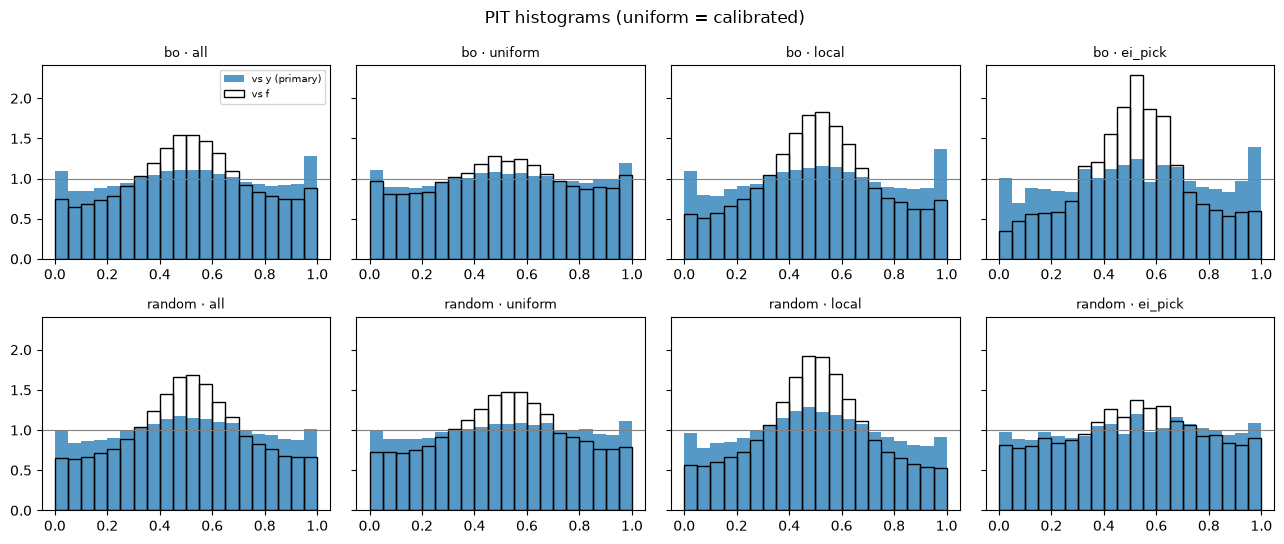

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharey=True)
for i, des in enumerate(("bo", "random")):
    for j, pt in enumerate(("all", "uniform", "local", "ei_pick")):
        ax = axes[i, j]
        for target, kw in (("y", dict(alpha=0.75, label="vs y (primary)")), ("f", dict(fill=False, edgecolor="k", label="vs f"))):
            h = hist[(hist.design == des) & (hist.ptype == pt) & (hist.target == target)].sort_values("bin")
            ax.bar(h["bin"] / 20 + 0.025, h.density, width=0.05, **kw)
        ax.axhline(1, color="grey", lw=0.8)
        ax.set_title(f"{des} · {pt}", fontsize=9)
axes[0, 0].legend(fontsize=7)
fig.suptitle("PIT histograms (uniform = calibrated)")
plt.tight_layout()

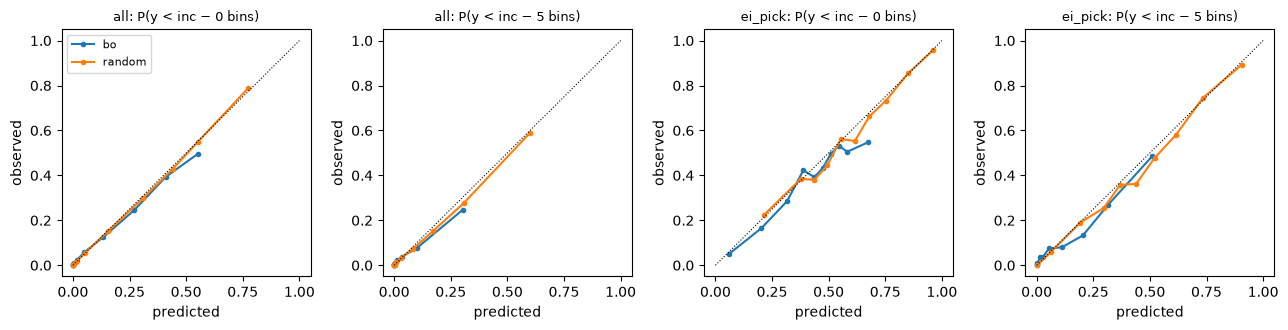

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (pt, k) in zip(axes, [("all", 0), ("all", 5), ("ei_pick", 0), ("ei_pick", 5)]):
    for des, c in (("bo", "C0"), ("random", "C1")):
        g = relia[(relia.design == des) & (relia.ptype == pt) & (relia.k == k)].sort_values("decile")
        ax.plot(g.p, g.o, "o-", color=c, label=des, ms=3)
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_title(f"{pt}: P(y < inc − {k} bins)", fontsize=9)
    ax.set_xlabel("predicted"); ax.set_ylabel("observed")
axes[0].legend(fontsize=8)
plt.tight_layout()

### Calibration by step t (a function of the context, so a valid conditioning variable)

In [ ]:
order = ["0-4", "5-9", "10-14", "15-19"]
T_ = by_t.assign(t_bin=pd.Categorical(by_t.t_bin, order, ordered=True)).set_index(["ptype", "t_bin", "design"])
display(T_[["cov90", "cov50", "citl_k0", "n"]].unstack("design").sort_index().round(3))

cov90         cov50        citl_k0             n       
design            bo random     bo random      bo random     bo random
ptype   t_bin                                                         
ei_pick 0-4    0.904  0.899  0.558  0.545   0.036  0.027   1069   1069
        5-9    0.895  0.909  0.547  0.498   0.060  0.004    967    967
        10-14  0.873  0.911  0.538  0.538   0.010  0.016    975    975
        15-19  0.847  0.870  0.503  0.485   0.037  0.023    989    989
local   0-4    0.930  0.927  0.608  0.600   0.014  0.002  17104  17104
        5-9    0.892  0.918  0.548  0.578   0.018 -0.006  15472  15472
        10-14  0.853  0.899  0.495  0.562   0.005  0.000  15600  15600
        15-19  0.831  0.879  0.473  0.529   0.012  0.000  15824  15824
uniform 0-4    0.902  0.906  0.532  0.532   0.008  0.005  17104  17104
        5-9    0.892  0.896  0.521  0.522   0.004  0.000  15472  15472
        10-14  0.876  0.894  0.501  0.527  -0.001  0.001  15600  15600
        15-19  0.870  0.879  0.495  0.502  -0.001  0.001  15824  15824

### Descriptive only: log density by gap stratum

These strata condition on f\* (not a function of the context), so they say where the predictive is sharp or poor, not whether it is calibrated.

In [ ]:
display(by_s.set_index(["stratum", "ptype", "design"]).unstack("design").round(3))

log_density        log_density_f         cov90             n  \
design                   bo random            bo random     bo random     bo   
stratum ptype                                                                  
1-10    ei_pick       3.164  2.175         3.293  2.174  0.930  0.919    690   
        local         3.343  2.978         3.469  3.063  0.904  0.918  11040   
        uniform       1.505  1.704         1.537  1.743  0.901  0.900  11040   
10-100  ei_pick       1.817  1.430         1.880  1.441  0.894  0.906    754   
        local         2.645  2.487         2.743  2.540  0.898  0.928  12064   
        uniform       1.073  1.317         1.087  1.342  0.861  0.897  12064   
<1      ei_pick       3.975  3.052         4.718  3.208  0.872  0.895   2298   
        local         3.884  3.735         4.375  4.042  0.865  0.898  36768   
        uniform       2.510  2.998         2.634  3.244  0.900  0.894  36768   
>100    ei_pick       0.460  0.566         0.565  0.597  0.771  0.829    258   
        local         1.815  1.802         1.928  1.859  0.855  0.883   4128   
        uniform       0.687  0.988         0.704  1.015  0.784  0.873   4128   

                       member         
design          random     bo random  
stratum ptype                         
1-10    ei_pick    690      0      0  
        local    11040      0      0  
        uniform  11040      0      0  
10-100  ei_pick    754      0      0  
        local    12064      0      0  
        uniform  12064      0      0  
<1      ei_pick   2298      0      0  
        local    36768      0      0  
        uniform  36768      0      0  
>100    ei_pick    258      0      0  
        local     4128      0      0  
        uniform   4128      0      0

## 2. Test 1: labels and headroom by resolution (gap stratum, in PFN bins)

In [ ]:
display(strata.assign(cell=strata.apply(lambda r: f"{r.value:.3f}" + ("" if np.isnan(r.lo) else f" [{r.lo:.3f}, {r.hi:.3f}]"), axis=1))
        .pivot_table(index="metric", columns="stratum", values="cell", aggfunc="first")[["all", "<1", "1-10", "10-100", ">100"]])
display(strata.drop_duplicates("stratum").set_index("stratum").n_states.rename("states").to_frame().T)

stratum,all,<1,1-10,10-100,>100
metric,,,,,
frac_adv_below_bin,0.907,1.000,0.917,0.727,0.582
headroom,"0.700 [0.573, 0.828]","0.025 [0.021, 0.031]","0.400 [0.304, 0.518]","2.058 [1.617, 2.621]","3.547 [2.350, 5.039]"
headroom_sum_share,1.000,0.021,0.098,0.554,0.327
reliability,"0.568 [0.552, 0.580]","0.642 [0.624, 0.659]","0.578 [0.553, 0.605]","0.462 [0.438, 0.488]","0.406 [0.369, 0.453]"
spearman_log_ei,"0.063 [0.052, 0.074]","0.073 [0.055, 0.088]","0.068 [0.049, 0.092]","0.042 [0.018, 0.062]","0.054 [0.007, 0.097]"
spearman_pi,"0.063 [0.050, 0.075]","0.092 [0.075, 0.111]","0.074 [0.049, 0.093]","0.005 [-0.017, 0.032]","0.018 [-0.021, 0.053]"


stratum,all,<1,1-10,10-100,>100
states,4000,2298,690,754,258


In [ ]:
# the api_decoder pilot's validation scores (q0.5), joined by task seed where its validation states are among these
try:
    val = pd.read_parquet("../results/api_decoder/pilot_20261111-165340/tables/val.parquet")
    v = val[val.valid & (val.j > 0)].merge(St[["seed", "stratum"]], on="seed")
    print("decoder validation states among these:", v.seed.nunique(), "of", val.seed.nunique())
    rows = []
    for s in ["all", "<1", "1-10", "10-100", ">100"]:
        V = v if s == "all" else v[v.stratum == s]
        if V.seed.nunique() < 5:
            continue
        rho = within_spearman(V["q0.5"].to_numpy(), V.adv.to_numpy(), V.seed.to_numpy())
        rho = rho[np.isfinite(rho)]
        rng = np.random.default_rng(0)
        b = [rho[rng.integers(0, len(rho), len(rho))].mean() for _ in range(500)]
        rows.append({"stratum": s, "states": len(rho), "spearman_q0.5": rho.mean(), "lo": np.percentile(b, 2.5), "hi": np.percentile(b, 97.5)})
    display(pd.DataFrame(rows).round(3))
except FileNotFoundError as e:
    print("skipped:", e)

decoder validation states among these: 430 of 1204


/home/ruhkopf/PycharmProjects/anytime-acquisition-api/src/anytime_acq/experimental/probes.py:262: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out.append(spearmanr(pred[m], y[m]).statistic)


,stratum,states,spearman_q0.5,lo,hi
0,all,328,0.086,0.050,0.123
1,<1,159,0.077,0.026,0.127
2,1-10,66,0.157,0.074,0.238
3,10-100,74,0.060,-0.016,0.133
4,>100,29,0.038,-0.052,0.154


## Observations (pilot, snapshot `results/pfn_bo_inference/pilot_20261112-084114`)

Written after the run. Numbers were read from the first pilot run, `pilot_20261112-083546`. That run was repeated as `pilot_20261112-084114` because its per-point table exceeded the 2 MB repo file limit; the per-point scores are now an artifact and the notebook reads aggregated tables. The calibration and strata tables reproduce exactly (max abs diff 0).
- **Checks.** 4000 states and 264 000 scored points.
  - The redrawn tasks reproduce the label set's observations (max |Δ| 1.2e-5, fp32 rounding).
  - The random-design control is calibrated where it should be: pooled cov90 0.900 [0.896, 0.904], cov50 0.544, every event ECE ≤ 0.008.
- **Test 2, the verdict: GO (E2 supported), but by a narrow margin.**
  - The rule fires on one criterion only: the 50% coverage at EI's picks on BO contexts, 0.537 [0.521, 0.551], against 0.517 for the random design.
  - Everything else at EI's picks is within tolerance or not distinguishable from the control:
    - cov90 0.880 [0.869, 0.889];
    - ECE of improvement (k = 0) 0.043 vs 0.024, difference 0.019 [−0.001, 0.027];
    - calibration-in-the-large +0.036 [0.019, 0.049], i.e. the PFN is slightly too optimistic about improving on the incumbent at the point EI picks, vs +0.018 for the control.
  - Pooled over all points, BO contexts are calibrated within the pre-registered tolerance: cov90 0.881, cov50 0.523, ECE ≤ 0.013.
  - The random design is calibrated, so by the pre-registered reading this is E2 at BO contexts. Its size is a few points of coverage, not a gross failure.
- **Where it sits (by step t, a valid conditioning variable).**
  - The BO-specific under-coverage grows late in the run, at points near the incumbent.
  - Local points, cov90 on BO vs random:
    - t 0–4: 0.930 vs 0.927;
    - t 10–14: 0.853 vs 0.899;
    - t 15–19: 0.831 vs 0.879.
  - Late in a run, with data clustered around the incumbent, the PFN is overconfident there. The uniform points stay close to the control at every t.
- **Descriptive (gap strata, conditioned on f\*, so not a calibration test).**
  - BO contexts are sharper near the incumbent: log density at EI's pick 3.20 vs 2.44 for the random design.
  - Where the gap is > 100 bins, coverage is poor for both designs (BO 0.77 / random 0.83 at EI picks). This is what conditioning on a far-from-optimum incumbent does, and is expected even for an exact posterior.
- **Test 1, resolution.**
  - **E4 signature present.**
    - 91% of the non-base advantages are below one bin (100% in the < 1-bin stratum).
    - The < 1-bin stratum holds 57% of the states (2298).
  - **But the headroom is not there.**
    - The < 1-bin states carry 2.1% of the clairvoyant headroom sum: mean 0.025 [0.021, 0.031] % of the gap.
    - The 10–100 and > 100-bin strata hold 25% of the states but 88% of the headroom: means 2.06 [1.62, 2.62] and 3.55 [2.35, 5.04].
    - The headroom lives where the gap is large and the advantages are mostly resolvable (27–42% of them above one bin).
  - **E3 not supported.**
    - In the ≥ 10-bin strata, the within-state Spearman of log EI with the label is 0.042 [0.018, 0.062] and 0.054 [0.007, 0.097]; PI gives 0.005 and 0.018. The pre-registered bar of CI lower bound > 0.10 is not met.
    - In the < 1-bin stratum the ranking is no worse: log EI 0.073, PI 0.092.
    - So resolution is not what makes the advantage unpredictable.
    - The decoder's q0.5 (430 of its 1204 validation states are among these 4000; 328 with a defined Spearman) shows no resolution pattern either: 0.157 [0.074, 0.238] at 1–10 bins, 0.04–0.08 elsewhere.
  - Label reliability *falls* with the gap: 0.64 in < 1 bin vs 0.41 in > 100. Where the headroom is, the labels are noisiest. With M = 4 continuations, the large-gap headroom is partly selection on noise.
- **Reading.**
  - The PFN does reasonable inference from BO data: pooled calibration is within tolerance.
  - Its BO-specific error is modest, sits late in the run near the incumbent, and is somewhat optimistic about improvement at EI's picks. That is E2, but small.
  - The resolution explanations do not account for the unpredictability:
    - E4: the sub-bin labels carry almost none of the headroom;
    - E3: the ranking is no better where the gap is resolvable.
  - Whether a calibration error of this size can hide the large-gap headroom (E2), or that headroom is irreducible given D (E1), is not decided here. That is test 3 of decision 0007: a variance-reduced lookahead restricted to the large-gap states, where the headroom is.


## Verdict

In [ ]:
v = inference_verdict(cal, con, KS)
print("verdict (analysis/inference.py::inference_verdict, test 2):", v)
for pt in ("all", "ei_pick"):
    print(f"  {pt}: BO miscalibrated={miscalibrated(cal, con, KS, pt)}, BO calibrated within tolerance={calibrated(cal, con, KS, pt)}")
rnd = cal[(cal.design == "random") & cal.ptype.isin(["all", "ei_pick"]) & cal.metric.isin(["cov50", "cov90"])]
print("random-design coverage (control):"); display(rnd[["ptype", "metric", "value", "lo", "hi"]].round(3))

verdict (analysis/inference.py::inference_verdict, test 2): GO
  all: BO miscalibrated=False, BO calibrated within tolerance=True
  ei_pick: BO miscalibrated=True, BO calibrated within tolerance=False
random-design coverage (control):


,ptype,metric,value,lo,hi
5,all,cov50,0.544,0.538,0.549
7,all,cov90,0.900,0.896,0.904
83,ei_pick,cov50,0.518,0.501,0.532
85,ei_pick,cov90,0.897,0.888,0.906
